<a href="https://colab.research.google.com/github/salmann6/231230052-Salman-Al-Farizi-Pengantar-ML/blob/main/Praktikum_XGBoost_Kolkata.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Klasifikasi Hujan Harian Kolkata dengan XGBoost + Dashboard Streamlit
**Dataset:** [Kolkata Climate and Weather 2021–2025 (Daily)](https://www.kaggle.com/datasets/sumanbera19/kolkata-climate-and-weather-20212025-daily-data)

**Rumusan masalah:** memprediksi apakah suatu hari **hujan** (`rain_sum` ≥ 1 mm → kelas 1) atau **tidak hujan** (kelas 0) memakai data suhu, angin, durasi sinar matahari, panjang hari, dan musim.

> **Catatan data leakage:** kolom `weather_code`, `precipitation_sum`, `rain_sum`, dan `precipitation_hours` secara langsung menggambarkan hujan, sehingga **tidak dipakai sebagai fitur**. Kolom `city`, `latitude`, `longitude` nilainya konstan, jadi dibuang.

## Persiapan: instal library & upload dataset

In [1]:
!pip install -q streamlit xgboost seaborn scikit-learn pandas matplotlib

In [2]:
from google.colab import files
uploaded = files.upload()   # pilih file kolkata_weather_jan_june_2026.csv (atau CSV dari Kaggle)
CSV_PATH = list(uploaded.keys())[0]
print("File dimuat:", CSV_PATH)

Saving kolkata_weather_jan_june_2026.csv to kolkata_weather_jan_june_2026.csv
File dimuat: kolkata_weather_jan_june_2026.csv


> Kalau file tidak bernama `kolkata_weather_jan_june_2026.csv`, ubah nama file di Colab (atau ganti `CSV_PATH` di bagian `app.py` nanti) supaya dashboard bisa menemukannya.

## Langkah 1 — Pemahaman dan Pengambilan Dataset

In [3]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings; warnings.filterwarnings("ignore")

df = pd.read_csv(CSV_PATH)
print("Jumlah baris & kolom:", df.shape)
df.head()

Jumlah baris & kolom: (1827, 17)


,time,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunrise,sunset,sunshine_duration,city,latitude,longitude
0,2021-06-30,65,29.9,33.4,28.0,11.6,11.6,6.0,23.7,46.1,206,2021-06-30T04:55,2021-06-30T18:25,20837.76,Kolkata,22.5726,88.3639
1,2021-07-01,63,29.8,33.4,27.8,10.5,10.5,10.0,19.1,37.1,193,2021-07-01T04:55,2021-07-01T18:25,21439.24,Kolkata,22.5726,88.3639
2,2021-07-02,63,29.2,32.2,27.8,15.9,15.9,13.0,18.7,33.8,209,2021-07-02T04:56,2021-07-02T18:25,12291.52,Kolkata,22.5726,88.3639
3,2021-07-03,63,29.2,32.9,27.3,7.6,7.6,11.0,15.5,32.0,202,2021-07-03T04:56,2021-07-03T18:25,29486.65,Kolkata,22.5726,88.3639
4,2021-07-04,63,28.6,32.1,26.9,8.0,8.0,11.0,12.0,29.5,180,2021-07-04T04:56,2021-07-04T18:25,41145.46,Kolkata,22.5726,88.3639


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1827 entries, 0 to 1826
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   time                         1827 non-null   object 
 1   weather_code                 1827 non-null   int64  
 2   temperature_2m_mean          1827 non-null   float64
 3   temperature_2m_max           1827 non-null   float64
 4   temperature_2m_min           1827 non-null   float64
 5   precipitation_sum            1827 non-null   float64
 6   rain_sum                     1827 non-null   float64
 7   precipitation_hours          1827 non-null   float64
 8   wind_speed_10m_max           1827 non-null   float64
 9   wind_gusts_10m_max           1827 non-null   float64
 10  wind_direction_10m_dominant  1827 non-null   int64  
 11  sunrise                      1827 non-null   object 
 12  sunset                       1827 non-null   object 
 13  sunshine_duration 

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
weather_code,1827.0,34.143952,2.899722e+01,0.0000,3.0000,51.0000,63.0000,65.0000
temperature_2m_mean,1827.0,26.264860,4.050220e+00,15.0000,23.4000,27.4000,29.1000,35.2000
temperature_2m_max,1827.0,31.099234,3.924558e+00,19.6000,28.7000,31.3000,33.3000,43.9000
temperature_2m_min,1827.0,22.477066,4.847343e+00,10.2000,18.6000,24.6000,26.2000,30.6000
precipitation_sum,1827.0,5.429119,9.550693e+00,0.0000,0.0000,0.4000,7.3500,80.5000
rain_sum,1827.0,5.429119,9.550693e+00,0.0000,0.0000,0.4000,7.3500,80.5000
precipitation_hours,1827.0,4.952928,6.275264e+00,0.0000,0.0000,2.0000,9.0000,24.0000
wind_speed_10m_max,1827.0,13.782157,5.106847e+00,4.5000,10.0000,12.6000,16.6000,44.0000
wind_gusts_10m_max,1827.0,30.756596,9.081119e+00,11.5000,24.1000,29.5000,36.0000,83.9000
wind_direction_10m_dominant,1827.0,192.212917,1.001658e+02,0.0000,135.0000,188.0000,258.0000,360.0000


**Pembentukan target & fitur.** Kita membuat kolom `hujan` (biner) dari `rain_sum`, serta beberapa fitur turunan:
- `panjang_hari_jam` = sunset − sunrise (jam)
- `sunshine_jam` = `sunshine_duration` dibagi 3600 (detik → jam)
- `musim` (kategorikal) dari bulan: Dingin (Des–Feb), Panas (Mar–Mei), Monsun (Jun–Sep), Pasca-Monsun (Okt–Nov)

In [6]:
MUSIM = ["Dingin", "Panas", "Monsun", "Pasca-Monsun"]
FITUR_NUM = ["temperature_2m_mean", "temperature_2m_max", "temperature_2m_min",
             "wind_speed_10m_max", "wind_gusts_10m_max", "wind_direction_10m_dominant",
             "sunshine_jam", "panjang_hari_jam"]

def musim_dari_bulan(m):
    if m in (12, 1, 2): return "Dingin"
    if m in (3, 4, 5): return "Panas"
    if m in (6, 7, 8, 9): return "Monsun"
    return "Pasca-Monsun"

def siapkan(df):
    df = df.copy()
    df["time"] = pd.to_datetime(df["time"])
    df["sunrise"] = pd.to_datetime(df["sunrise"])
    df["sunset"] = pd.to_datetime(df["sunset"])
    df["panjang_hari_jam"] = (df["sunset"] - df["sunrise"]).dt.total_seconds() / 3600
    df["sunshine_jam"] = df["sunshine_duration"] / 3600
    df["musim"] = pd.Categorical(df["time"].dt.month.map(musim_dari_bulan), categories=MUSIM)
    df["hujan"] = (df["rain_sum"] >= 1).astype(int)   # TARGET
    return df

df = siapkan(df)
print("Fitur (X) :", FITUR_NUM + ["musim"])
print("Target (y): hujan  (1 = hujan >= 1 mm, 0 = tidak hujan)")
df[["time"] + FITUR_NUM + ["musim", "rain_sum", "hujan"]].head()

Fitur (X) : ['temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'wind_speed_10m_max', 'wind_gusts_10m_max', 'wind_direction_10m_dominant', 'sunshine_jam', 'panjang_hari_jam', 'musim']
Target (y): hujan  (1 = hujan >= 1 mm, 0 = tidak hujan)


,time,temperature_2m_mean,temperature_2m_max,temperature_2m_min,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunshine_jam,panjang_hari_jam,musim,rain_sum,hujan
0,2021-06-30,29.9,33.4,28.0,23.7,46.1,206,5.788267,13.500000,Monsun,11.6,1
1,2021-07-01,29.8,33.4,27.8,19.1,37.1,193,5.955344,13.500000,Monsun,10.5,1
2,2021-07-02,29.2,32.2,27.8,18.7,33.8,209,3.414311,13.483333,Monsun,15.9,1
3,2021-07-03,29.2,32.9,27.3,15.5,32.0,202,8.190736,13.483333,Monsun,7.6,1
4,2021-07-04,28.6,32.1,26.9,12.0,29.5,180,11.429294,13.483333,Monsun,8.0,1


## Langkah 2 — Eksplorasi Data (EDA)

### 2.1 Missing values

In [7]:
print(df[FITUR_NUM + ["musim", "hujan"]].isna().sum())
print("\nTotal missing:", df[FITUR_NUM + ["musim", "hujan"]].isna().sum().sum())

temperature_2m_mean            0
temperature_2m_max             0
temperature_2m_min             0
wind_speed_10m_max             0
wind_gusts_10m_max             0
wind_direction_10m_dominant    0
sunshine_jam                   0
panjang_hari_jam               0
musim                          0
hujan                          0
dtype: int64

Total missing: 0


Dataset ini **tidak memiliki nilai kosong**, jadi tidak perlu imputasi. (Jika ada, fitur numerik bisa diisi median dan kategorikal diisi modus, dilakukan **setelah** split dan hanya dihitung dari data latih.)

### 2.2 Distribusi fitur

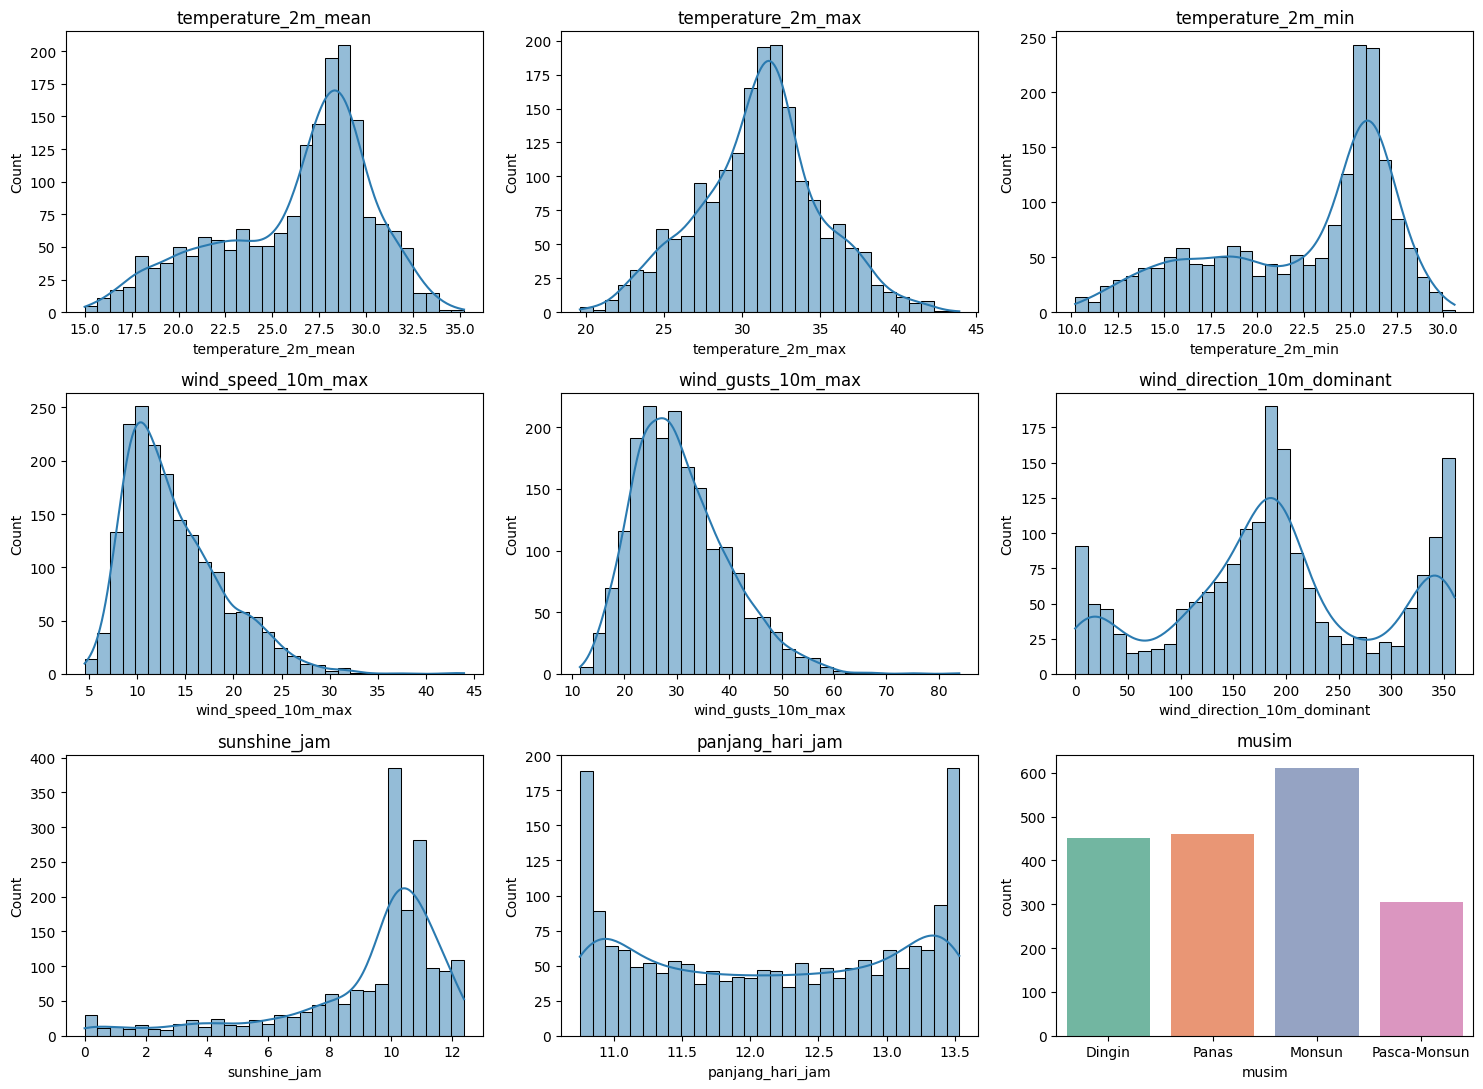

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, f in zip(axes.ravel(), FITUR_NUM):
    sns.histplot(df[f], kde=True, bins=30, ax=ax, color="#2a7ab0")
    ax.set_title(f)
sns.countplot(x="musim", data=df, ax=axes.ravel()[-1], palette="Set2")
axes.ravel()[-1].set_title("musim")
plt.tight_layout(); plt.show()

### 2.3 Proporsi kelas target

hujan
Tidak hujan    0.539
Hujan          0.461
Name: proportion, dtype: float64


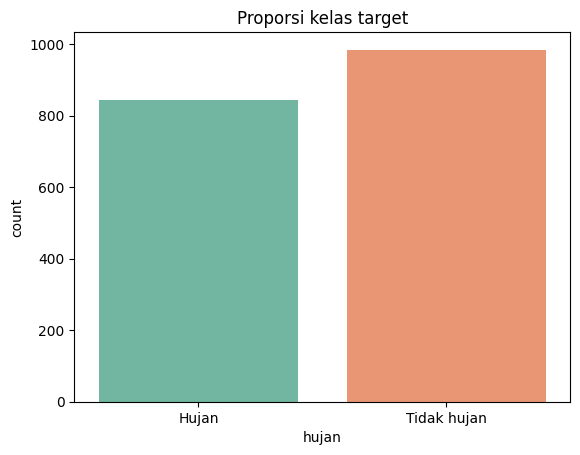

In [9]:
print(df["hujan"].value_counts(normalize=True).rename({0: "Tidak hujan", 1: "Hujan"}).round(3))
sns.countplot(x=df["hujan"].map({0: "Tidak hujan", 1: "Hujan"}), palette="Set2")
plt.title("Proporsi kelas target"); plt.show()

Kelas relatif seimbang (± 46% hujan vs 54% tidak hujan), sehingga tidak perlu teknik penyeimbangan seperti SMOTE.

### 2.4 Heatmap korelasi

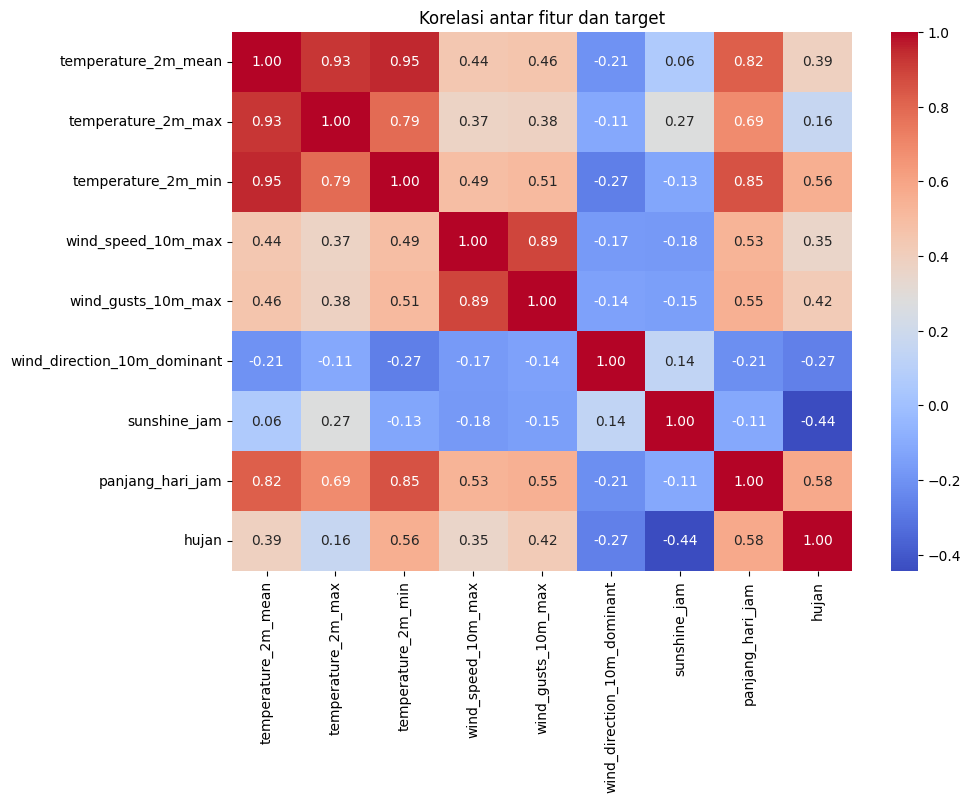

In [10]:
plt.figure(figsize=(10, 7))
sns.heatmap(df[FITUR_NUM + ["hujan"]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Korelasi antar fitur dan target"); plt.show()

## Langkah 3 — Pra-Pemrosesan Data

- **Encoding:** `musim` (kategorikal) di-*one-hot encode*. Kolom `city` konstan sehingga dibuang.
- **Standarisasi:** *tidak diperlukan* karena XGBoost berbasis pohon keputusan (tidak sensitif terhadap skala fitur).
- **Split:** 80% latih / 20% uji dengan `stratify=y` agar proporsi kelas sama di kedua bagian.
- **Anti-leakage:** `weather_code`, `precipitation_sum`, `rain_sum`, `precipitation_hours` dikeluarkan dari fitur.

In [11]:
def encode(d):
    return pd.get_dummies(d[FITUR_NUM + ["musim"]], columns=["musim"], dtype=int)

X = encode(df)
y = df["hujan"]
print("Kolom fitur akhir:", list(X.columns))

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)
print("Proporsi hujan -> latih: %.3f | uji: %.3f" % (y_train.mean(), y_test.mean()))

Kolom fitur akhir: ['temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'wind_speed_10m_max', 'wind_gusts_10m_max', 'wind_direction_10m_dominant', 'sunshine_jam', 'panjang_hari_jam', 'musim_Dingin', 'musim_Panas', 'musim_Monsun', 'musim_Pasca-Monsun']
Data latih: (1461, 12) | Data uji: (366, 12)
Proporsi hujan -> latih: 0.461 | uji: 0.462


## Langkah 4 — Membangun Model XGBoost

In [12]:
from xgboost import XGBClassifier

model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42,
    eval_metric="logloss",
)
model.fit(X_train, y_train)

y_pred  = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]
print("Model selesai dilatih.")

Model selesai dilatih.


## Langkah 5 — Evaluasi Model

In [13]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report)

hasil = {
    "Accuracy":  accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall":    recall_score(y_test, y_pred),
    "F1-Score":  f1_score(y_test, y_pred),
    "ROC-AUC":   roc_auc_score(y_test, y_proba),
}
tabel_metrik = pd.DataFrame({"Metrik": hasil.keys(), "Nilai": [round(v, 4) for v in hasil.values()]})
display(tabel_metrik)
print(classification_report(y_test, y_pred, target_names=["Tidak hujan", "Hujan"]))
print("Akurasi data latih: %.4f | akurasi data uji: %.4f" %
      (accuracy_score(y_train, model.predict(X_train)), hasil["Accuracy"]))

,Metrik,Nilai
0,Accuracy,0.8962
1,Precision,0.8970
2,Recall,0.8757
3,F1-Score,0.8862
4,ROC-AUC,0.9660


              precision    recall  f1-score   support

 Tidak hujan       0.90      0.91      0.90       197
       Hujan       0.90      0.88      0.89       169

    accuracy                           0.90       366
   macro avg       0.90      0.89      0.90       366
weighted avg       0.90      0.90      0.90       366

Akurasi data latih: 0.9911 | akurasi data uji: 0.8962


**Cara menginterpretasi:**
- **Accuracy** tinggi → model mengklasifikasikan sebagian besar hari dengan benar.
- **Precision** → dari semua hari yang diprediksi hujan, berapa persen yang benar-benar hujan.
- **Recall** → dari semua hari hujan yang sebenarnya, berapa persen yang berhasil terdeteksi.
- **F1-Score** tinggi → precision dan recall seimbang.
- **ROC-AUC** mendekati 1 → model sangat baik membedakan hari hujan dan tidak hujan.
- Jika akurasi latih jauh lebih tinggi daripada akurasi uji, itu tanda **overfitting**.

## Langkah 6 — Visualisasi Hasil

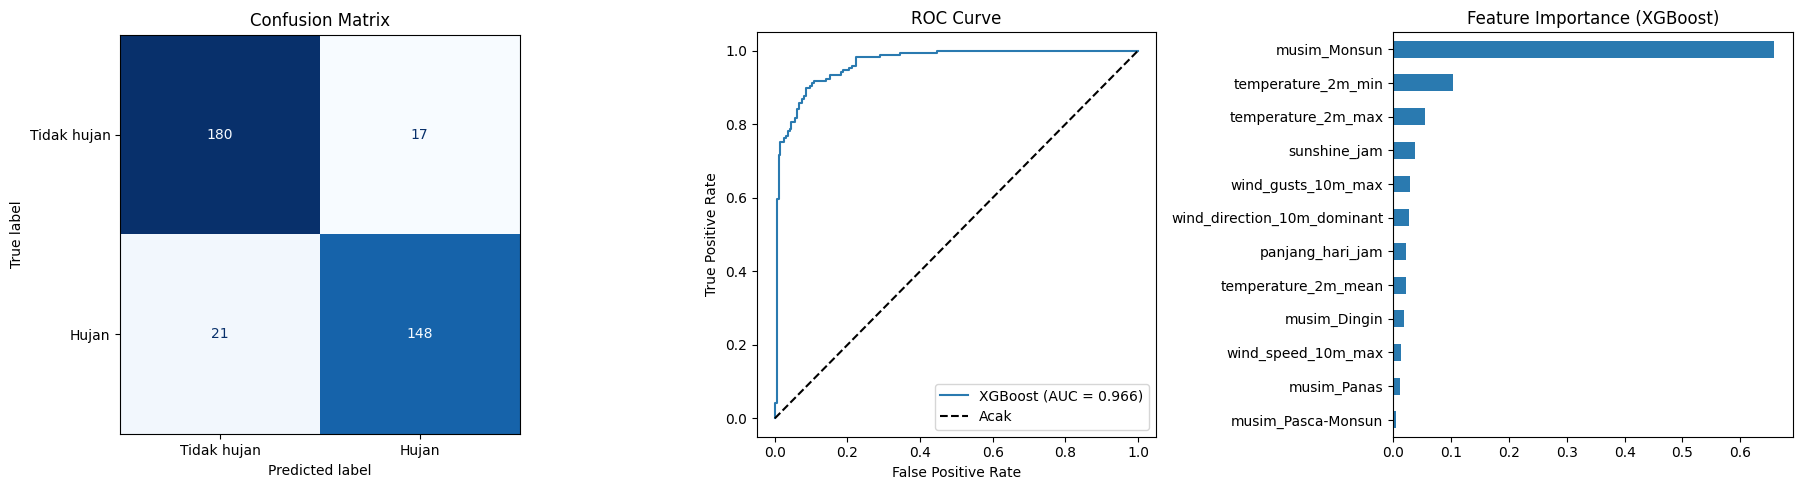

In [14]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Confusion matrix
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=["Tidak hujan", "Hujan"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion Matrix")

# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, label="XGBoost (AUC = %.3f)" % hasil["ROC-AUC"], color="#2a7ab0")
axes[1].plot([0, 1], [0, 1], "k--", label="Acak")
axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC Curve"); axes[1].legend()

# Feature importance
imp = pd.Series(model.feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", ax=axes[2], color="#2a7ab0")
axes[2].set_title("Feature Importance (XGBoost)")
plt.tight_layout(); plt.show()

**Analisis singkat** (isi sesuai hasil yang muncul di notebook kamu): sebutkan fitur dengan importance tertinggi, jelaskan apakah masuk akal secara meteorologi (misalnya durasi sinar matahari yang rendah dan musim Monsun biasanya berkaitan dengan hari hujan), dan bandingkan nilai precision vs recall.

## Langkah 7 — Dashboard Streamlit
Kode dashboard ditulis ke file `app.py`. Dashboard melatih ulang model dengan konfigurasi yang sama (seed 42, split 80/20) sehingga hasilnya konsisten dengan notebook.

In [15]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve, ConfusionMatrixDisplay)

st.set_page_config(page_title="Klasifikasi Hujan Kolkata", page_icon="🌧️", layout="wide")

CSV_PATH = "kolkata_weather_jan_june_2026.csv"
MUSIM = ["Dingin", "Panas", "Monsun", "Pasca-Monsun"]
FITUR_NUM = ["temperature_2m_mean", "temperature_2m_max", "temperature_2m_min",
             "wind_speed_10m_max", "wind_gusts_10m_max", "wind_direction_10m_dominant",
             "sunshine_jam", "panjang_hari_jam"]


def musim_dari_bulan(m):
    if m in (12, 1, 2): return "Dingin"
    if m in (3, 4, 5): return "Panas"
    if m in (6, 7, 8, 9): return "Monsun"
    return "Pasca-Monsun"


def siapkan(df):
    df = df.copy()
    df["time"] = pd.to_datetime(df["time"])
    df["sunrise"] = pd.to_datetime(df["sunrise"])
    df["sunset"] = pd.to_datetime(df["sunset"])
    df["panjang_hari_jam"] = (df["sunset"] - df["sunrise"]).dt.total_seconds() / 3600
    df["sunshine_jam"] = df["sunshine_duration"] / 3600
    df["musim"] = pd.Categorical(df["time"].dt.month.map(musim_dari_bulan), categories=MUSIM)
    df["hujan"] = (df["rain_sum"] >= 1).astype(int)   # TARGET: 1 = hujan (>= 1 mm), 0 = tidak
    return df


def encode(df):
    return pd.get_dummies(df[FITUR_NUM + ["musim"]], columns=["musim"], dtype=int)


@st.cache_data
def muat_data():
    return siapkan(pd.read_csv(CSV_PATH))


@st.cache_resource
def latih_model(df):
    X, y = encode(df), df["hujan"]
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    model = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=5,
                          random_state=42, eval_metric="logloss")
    model.fit(X_tr, y_tr)
    return model, X_te, y_te, list(X.columns)


df = muat_data()
model, X_te, y_te, kolom = latih_model(df)
y_pred = model.predict(X_te)
y_proba = model.predict_proba(X_te)[:, 1]

# ---------------- Judul ----------------
st.title("🌧️ Klasifikasi Hujan Harian Kota Kolkata dengan XGBoost")
st.markdown(
    "Dashboard ini memprediksi apakah suatu hari **hujan** (curah hujan ≥ 1 mm) atau **tidak hujan** "
    "berdasarkan suhu, angin, durasi sinar matahari, panjang hari, dan musim. "
    "Data: *Kolkata Climate and Weather 2021–2025 (daily)* dari Kaggle. "
    "Kolom `weather_code`, `precipitation_*`, dan `rain_sum` **tidak dipakai sebagai fitur** "
    "agar tidak terjadi data leakage."
)

# ---------------- Ringkasan dataset ----------------
st.header("1. Ringkasan Dataset")
c1, c2, c3, c4 = st.columns(4)
c1.metric("Jumlah data", f"{len(df):,}")
c2.metric("Jumlah fitur", len(kolom))
c3.metric("Hari hujan", f"{df['hujan'].mean()*100:.1f}%")
c4.metric("Hari tidak hujan", f"{(1-df['hujan'].mean())*100:.1f}%")
st.caption(f"Periode data: {df['time'].min().date()} s/d {df['time'].max().date()}")
with st.expander("Lihat cuplikan data"):
    st.dataframe(df[["time"] + FITUR_NUM + ["musim", "rain_sum", "hujan"]].head(20))

# ---------------- EDA ----------------
st.header("2. Eksplorasi Data (EDA)")
tab1, tab2, tab3 = st.tabs(["Distribusi fitur", "Korelasi", "Proporsi kelas"])
with tab1:
    fitur_pilih = st.selectbox("Pilih fitur", FITUR_NUM)
    fig, ax = plt.subplots(figsize=(7, 3.5))
    sns.histplot(data=df, x=fitur_pilih, hue="hujan", kde=True, bins=30, ax=ax,
                 palette={0: "#f0a030", 1: "#2a7ab0"})
    ax.set_title(f"Distribusi {fitur_pilih} berdasarkan kelas (0 = tidak hujan, 1 = hujan)")
    st.pyplot(fig)
with tab2:
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(df[FITUR_NUM + ["hujan"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax)
    st.pyplot(fig)
with tab3:
    fig, ax = plt.subplots(figsize=(4.5, 3.5))
    sns.countplot(x=df["hujan"].map({0: "Tidak hujan", 1: "Hujan"}), hue=df["hujan"].map({0: "Tidak hujan", 1: "Hujan"}), ax=ax, palette="Set2", legend=False)
    ax.set_xlabel(""); ax.set_ylabel("Jumlah hari")
    st.pyplot(fig)

# ---------------- Performa ----------------
st.header("3. Performa Model")
metrik = {
    "Accuracy": accuracy_score(y_te, y_pred),
    "Precision": precision_score(y_te, y_pred),
    "Recall": recall_score(y_te, y_pred),
    "F1-Score": f1_score(y_te, y_pred),
    "ROC-AUC": roc_auc_score(y_te, y_proba),
}
cols = st.columns(5)
for col, (nama, nilai) in zip(cols, metrik.items()):
    col.metric(nama, f"{nilai:.3f}")
st.table(pd.DataFrame({"Metrik": metrik.keys(), "Nilai": [round(v, 4) for v in metrik.values()]}))

g1, g2 = st.columns(2)
with g1:
    st.subheader("Confusion Matrix")
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ConfusionMatrixDisplay(confusion_matrix(y_te, y_pred),
                           display_labels=["Tidak hujan", "Hujan"]).plot(ax=ax, cmap="Blues", colorbar=False)
    st.pyplot(fig)
with g2:
    st.subheader("ROC Curve")
    fpr, tpr, _ = roc_curve(y_te, y_proba)
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ax.plot(fpr, tpr, label=f"XGBoost (AUC = {metrik['ROC-AUC']:.3f})", color="#2a7ab0")
    ax.plot([0, 1], [0, 1], "k--", label="Acak")
    ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate"); ax.legend()
    st.pyplot(fig)

st.subheader("Feature Importance")
imp = pd.Series(model.feature_importances_, index=kolom).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
imp.plot(kind="barh", ax=ax, color="#2a7ab0")
ax.set_xlabel("Importance")
st.pyplot(fig)

# ---------------- Prediksi manual ----------------
st.header("4. Coba Prediksi Manual")
with st.form("form_prediksi"):
    a, b = st.columns(2)
    inp = {}
    for i, f in enumerate(FITUR_NUM):
        lo, hi, med = float(df[f].min()), float(df[f].max()), float(df[f].median())
        inp[f] = (a if i % 2 == 0 else b).slider(f, lo, hi, med)
    musim_in = st.selectbox("Musim", MUSIM, index=2)
    kirim = st.form_submit_button("Prediksi")

if kirim:
    baris = pd.DataFrame([inp])
    baris["musim"] = pd.Categorical([musim_in], categories=MUSIM)
    baris = encode(baris)[kolom]
    p = float(model.predict_proba(baris)[0, 1])
    if p >= 0.5:
        st.success(f"🌧️ Prediksi: **HUJAN** (probabilitas {p*100:.1f}%)")
    else:
        st.info(f"☀️ Prediksi: **TIDAK HUJAN** (probabilitas hujan {p*100:.1f}%)")
    st.progress(p)

Writing app.py


### Menjalankan dashboard di Colab
Colab tidak punya browser langsung, jadi kita buka lewat tunnel (`localtunnel`). Langkah:
1. Jalankan sel di bawah.
2. Salin **IP** yang tercetak (itu dipakai sebagai *password* tunnel).
3. Klik link `https://xxxx.loca.lt`, lalu masukkan IP tadi pada halaman yang meminta *Tunnel Password*.

In [ ]:
!npm install -q localtunnel
import urllib.request
print("Password tunnel (IP):", urllib.request.urlopen("https://ipv4.icanhazip.com").read().decode().strip())
!streamlit run app.py --server.port 8501 &>/content/logs.txt &
!npx localtunnel --port 8501

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸
added 22 packages in 6s
⠸
⠸3 packages are looking for funding
⠸  run `npm fund` for details
⠸Password tunnel (IP): 34.28.16.5
⠙⠹your url is: https://pink-yaks-hang.loca.lt


> Untuk menghentikan dashboard, tekan tombol stop pada sel di atas.

## Kesimpulan
Tulis kesimpulan akhir: performa model (accuracy, F1, ROC-AUC), fitur paling berpengaruh, keterbatasan (misalnya data hanya satu kota, split acak pada data deret waktu, dan target dibuat dari ambang 1 mm), serta saran pengembangan (tuning hyperparameter, validasi silang, atau split berbasis waktu).